# Thống kê Phân tích Cú pháp & Chuẩn hóa — Milestone 2

Chương này tổng hợp kết quả kiểm tra cấu trúc đa tệp (`.tex` / `.bib`) từ Corpus thu thập được và trình bày các bảng dữ liệu đầu ra (`elements`, `hierarchy`, `bibtex`) của Milestone 2.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

candidates = [
    Path("../metrics"),
    Path("metrics"),
    Path("../../data/metrics"),
]
metrics_dir = next((p for p in candidates if (p / "per_paper_metrics.json").is_file()), Path("../metrics"))
per_paper = json.loads((metrics_dir / "per_paper_metrics.json").read_text(encoding="utf-8"))["papers"]
df_papers = pd.DataFrame(per_paper)

# Thống kê cấu trúc file nguồn đầu vào cho Milestone 2 Parser
m2_input_summary = [
    {"Chỉ số Đầu vào Parser": "Tổng số bài báo đưa vào phân tích", "Giá trị": int(len(df_papers))},
    {"Chỉ số Đầu vào Parser": "Số bài báo có nhiều phiên bản (Multi-version Papers cần Deduplication)", "Giá trị": int((df_papers["versions_discovered"] > 1).sum())},
    {"Chỉ số Đầu vào Parser": "Số bài báo đa tệp .tex (Multi-file LaTeX cần gom \\input / \\include)", "Giá trị": int((df_papers["tex_files_count"] > 1).sum())},
    {"Chỉ số Đầu vào Parser": "Tổng số file .tex đầu vào", "Giá trị": int(df_papers["tex_files_count"].sum())},
    {"Chỉ số Đầu vào Parser": "Tổng số file .bib đầu vào", "Giá trị": int(df_papers["bib_files_count"].sum())},
]
pd.DataFrame(m2_input_summary)

,Chỉ số Đầu vào Parser,Giá trị
0,Tổng số bài báo đưa vào phân tích,5
1,Số bài báo có nhiều phiên bản (Multi-version P...,1
2,Số bài báo đa tệp .tex (Multi-file LaTeX cần g...,2
3,Tổng số file .tex đầu vào,38
4,Tổng số file .bib đầu vào,4


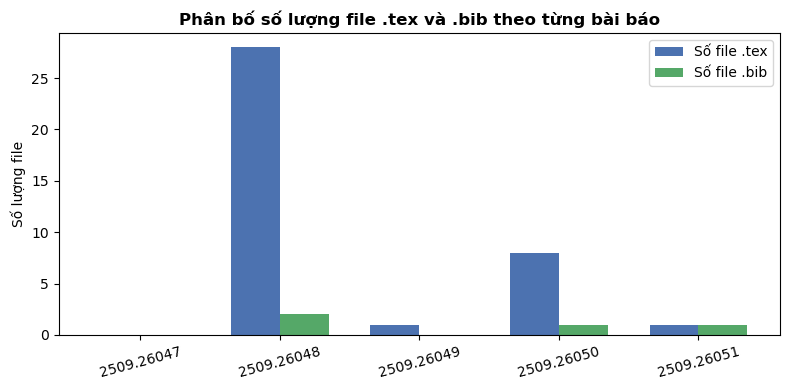

In [2]:
if not df_papers.empty:
    fig, ax = plt.subplots(figsize=(8, 4))
    x = range(len(df_papers))
    w = 0.35
    ax.bar([i - w/2 for i in x], df_papers["tex_files_count"], width=w, label="Số file .tex", color="#4C72B0")
    ax.bar([i + w/2 for i in x], df_papers["bib_files_count"], width=w, label="Số file .bib", color="#55A868")
    ax.set_xticks(list(x))
    ax.set_xticklabels(df_papers["arxiv_id"], rotation=15)
    ax.set_title("Phân bố số lượng file .tex và .bib theo từng bài báo", fontweight="bold")
    ax.set_ylabel("Số lượng file")
    ax.legend()
    plt.tight_layout()
    plt.show()

## Cấu trúc 3 Bảng Chuẩn hóa của Milestone 2

Dữ liệu sau khi phân tích cú pháp và khử trùng lặp được chuẩn hóa thành 3 bảng quan hệ:

In [3]:
schema_m2 = pd.DataFrame([
    {"Bảng (Table)": "elements", "Các cột chính (Columns)": "element_id (string), kind (document/heading/sentence/equation/figure/table), content (string)", "Ý nghĩa": "Kho lưu trữ chung các phần tử đã khử trùng lặp xuyên suốt các version"},
    {"Bảng (Table)": "hierarchy", "Các cột chính (Columns)": "arxiv_id (string), version (int), element_id (string), parent_id (string), order_index (int)", "Ý nghĩa": "Cấu trúc cây phân cấp của từng phiên bản v1..vN"},
    {"Bảng (Table)": "bibtex", "Các cột chính (Columns)": "arxiv_id (string), bib_key (string), entry_type (string), title (string), authors (list), year (int), doi (string)", "Ý nghĩa": "Danh mục tài liệu tham khảo chuẩn hóa BibTeX từ cả .bib và \\bibitem"},
])
schema_m2

,Bảng (Table),Các cột chính (Columns),Ý nghĩa
0,elements,"element_id (string), kind (document/heading/se...",Kho lưu trữ chung các phần tử đã khử trùng lặp...
1,hierarchy,"arxiv_id (string), version (int), element_id (...",Cấu trúc cây phân cấp của từng phiên bản v1..vN
2,bibtex,"arxiv_id (string), bib_key (string), entry_typ...",Danh mục tài liệu tham khảo chuẩn hóa BibTeX t...
